# Gotham's rogues, ranked

Mad Hatter has a better median rank than the Joker. Shark stories span the whole list, from #11 to #740. And "legitimate" shows up in five Penguin plots and nowhere else.

The list is [BatChat](https://comicsxf.com/batchat-rankings/), a podcast where **Matt Lazorwitz and Will Nevin** have read and ranked **740 Batman stories**. This notebook is about the cast: which heroes and villains turn up in the best books, whether that survives a closer look, and what the plot summaries say about each villain.

Companion to [Who gets the good Batman stories?](https://www.kaggle.com/code/danofer/who-gets-the-good-batman-stories), which covers writers, artists, and eras. **Rank 1 is best; lower is better throughout.**

<details><summary>Three words you'll see a lot</summary>

- **Rank**: position on BatChat's list. #1 is the best Batman story; #740 the worst. Lower is better everywhere here.
- **Median rank**: the typical rank for a group. Half the group's stories rank above it, half below.
- **Selected story**: an issue can hold several stories (a lead feature and a backup). We only count the one the podcast actually ranked, and the characters in *that* one.

</details>

By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ) · [Dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings) · [Code and sources](https://github.com/ddofer/BatRank) · snapshot of 21 October 2026

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
COLORS = {"blue": "#2767A0", "orange": "#D57927", "green": "#26806B", "grey": "#75818C"}
sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"},
)
pd.set_option("display.max_colwidth", 70)


def split_set(value):
    """Split a |-separated field into a list; missing values give an empty list."""
    return [item for item in value.split("|") if item] if isinstance(value, str) else []


def rank_summary(frame, by):
    """Count, median rank, and best/worst-ranked story titles per group."""
    return (
        frame.sort_values("rank")
        .groupby(by)
        .agg(
            n=("story_id", "nunique"),
            median_rank=("rank", "median"),
            best_rank=("rank", "first"),
            best_story=("title", "first"),
            worst_rank=("rank", "last"),
            worst_story=("title", "last"),
        )
    )


def rank_boxes(ax, entries, key, labels, color=COLORS["blue"]):
    """Box of the middle half plus one faint dot per story, in the order of `labels`."""
    chart = entries[entries[key].isin(labels.index)].assign(label=lambda d: d[key].map(labels))
    common = dict(data=chart, x="rank", y="label", order=labels.tolist(), ax=ax)
    sns.stripplot(**common, color=COLORS["grey"], alpha=0.35, size=3, jitter=False, zorder=0)
    sns.boxplot(**common, color=color, whis=0, showfliers=False, width=0.45)
    ax.set(xlabel="BatChat rank · 1 = best", ylabel="", xlim=(1, N))


PRETTY = {
    "display_name": "Character",
    "n": "Stories",
    "median_rank": "Median rank",
    "best_rank": "Best rank",
    "best_story": "Best-ranked story",
    "worst_rank": "Worst rank",
    "worst_story": "Worst-ranked story",
}


def collapsible(summary, table, note="", **to_html):
    """Show a long table inside a click-to-expand block."""
    body = table.to_html(escape=True, **to_html)
    return HTML(f"<details><summary>{summary}</summary><p>{note}</p>{body}</details>")


stories = pd.read_csv(DATA / "stories.csv")
N = len(stories)
print(f"{N:,} ranked stories · snapshot {stories.snapshot_date.iloc[0]}")

740 ranked stories · snapshot 2026-10-21


In [2]:
cast_known = stories[
    stories.cast_scope.eq("selected_narratives") & stories.cast_issue_coverage.eq(1)
].copy()
cast_known["decade"] = (cast_known.cover_year_start // 10 * 10).astype("Int64")

# These spellings identify the same character; each character counts once per story.
character_aliases = {
    "Edward Nashton": "Riddler",
    "Edward Nigma": "Riddler",
    "Edward Nygma": "Riddler",
    "Doctor Schivel": "Mr. Freeze",
    "Victor Fries": "Mr. Freeze",
    "Terrence McGinnis": "Terry McGinnis",
}
# Display names for civilian identities that readers know by another name.
display_names = {
    "Jervis Tetch": "Mad Hatter",
    "Selina Kyle": "Catwoman",
    "Victor Fries": "Mr. Freeze",
    "Oswald Cobblepot": "Penguin",
    "Pamela Isley": "Poison Ivy",
    "Harvey Dent": "Two-Face",
    "Jonathan Crane": "Scarecrow",
    "Harleen Quinzel": "Harley Quinn",
    "Waylon Jones": "Killer Croc",
    "Bruce Wayne": "Bruce Wayne / Batman",
    "Richard Grayson": "Dick Grayson",
    "Kal-El": "Superman",
    "Timothy Drake": "Tim Drake",
    "Diana of Themyscira": "Wonder Woman",
    "J'onn J'onzz": "Martian Manhunter",
    "Victor Sage": "The Question (Vic Sage)",
    "Michael Carter": "Booster Gold",
    "Theodore Kord": "Blue Beetle (Ted Kord)",
    "Roger Hayden": "Psycho-Pirate",
    "Dumpson Tweed": "Tweedledum",
    "Deever Tweed": "Tweedledee",
    "Raymond Palmer": "The Atom (Ray Palmer)",
    "Rex Mason": "Metamorpho",
    "Scott Free": "Mister Miracle",
    "Ted Grant": "Wildcat",
    "Thomas Blake": "Catman",
    "Aaron Helzinger": "Amygdala",
    "Simon Hurt": "Doctor Hurt",
    "Maximillian Zeus": "Maxie Zeus",
}


def entity_associations(frame, column):
    """One row per story and character, with universe suffixes such as '(New Earth)' removed."""
    out = frame[["story_id", "rank", "cover_year_start", column]].copy()
    out["entity"] = out[column].map(split_set)
    out = out.explode("entity").dropna(subset=["entity"])
    out["entity"] = out.entity.str.replace(r" \([^()]+\)$", "", regex=True)
    out["entity"] = out.entity.replace(character_aliases)
    return out.drop_duplicates(["story_id", "entity"])


entries = {
    "Featured cast": entity_associations(cast_known, "featured_entity_ids"),
    "Antagonists": entity_associations(cast_known, "antagonists_entity_ids"),
}
antagonists = entries["Antagonists"]
profiles = {}
for role, rows in entries.items():
    table = rank_summary(
        rows.merge(stories[["story_id", "title"]], on="story_id", validate="many_to_one"), "entity"
    )
    table["display_name"] = table.index.to_series().replace(display_names)
    profiles[role] = table.sort_values(["median_rank", "n"], ascending=[True, False])

## Which heroes and villains get the better stories?

**Barbara Gordon's stories rank better than Bruce Wayne's.** Her 52 featured appearances have a median rank of **235.5**; his 479 have **379**. Below: the **15 most frequent names in each role**, boxes = middle half of their stories' ranks. **Left is better.** The dotted line is the median of the 682 stories with complete character lists.

"Featured" usually means a hero, but villains can star too. "Antagonist" is a character's role in that story. Neither measures page time.

<details><summary>How names are counted</summary>

Cameos, mentions, flashbacks, and depictions are excluded. Each name counts once per story and role. Earth-2, New Earth, and Prime Earth versions of a character count as the same name; Riddler's Nashton/Nygma/Nigma spellings are merged, as are Mr. Freeze's and Terry McGinnis's variants.

</details>

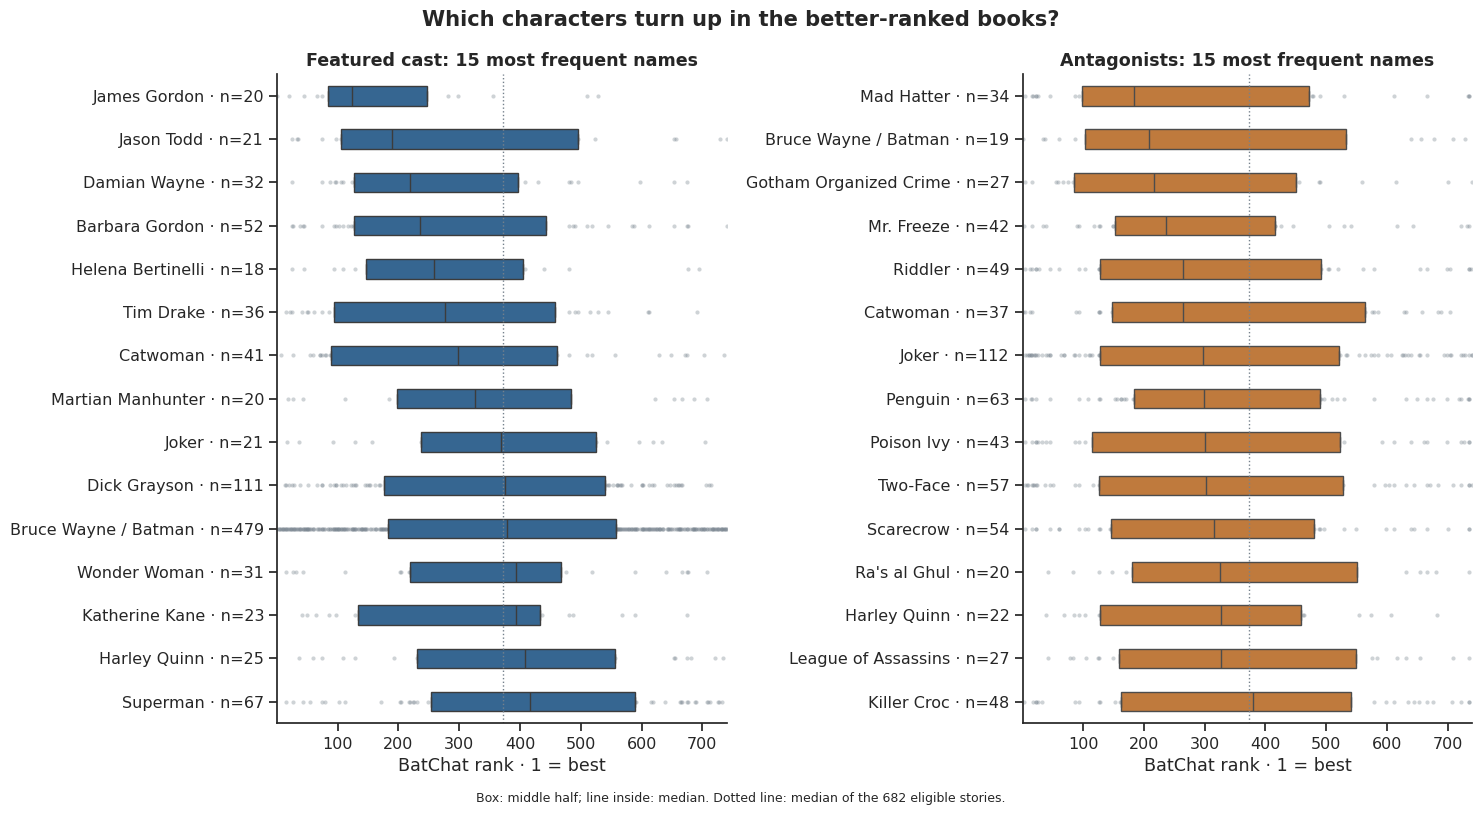

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharex=True)
for ax, (role, table), color in zip(axes, profiles.items(), [COLORS["blue"], COLORS["orange"]]):
    shown = table.nlargest(15, "n").sort_values("median_rank")
    rank_boxes(
        ax, entries[role], "entity", shown.display_name + " · n=" + shown.n.astype(str), color
    )
    ax.axvline(cast_known["rank"].median(), ls=":", color=COLORS["grey"], lw=1)
    ax.set_title(f"{role}: 15 most frequent names")
fig.suptitle("Which characters turn up in the better-ranked books?", fontweight="bold")
fig.text(
    0.5,
    -0.01,
    f"Box: middle half; line inside: median. Dotted line: median of the {len(cast_known)} eligible stories.",
    ha="center",
    fontsize=9,
)
fig.tight_layout()
plt.show()

In [4]:
print(
    "Full tables, every name (click to expand; one-story entries just inherit that story's rank):"
)
for role, table in profiles.items():
    shown = table[["display_name", "n", "median_rank", "best_rank", "worst_rank"]].rename(
        columns=PRETTY
    )
    display(
        collapsible(
            f"All {len(shown):,} {role.lower()} entries, sorted by median rank",
            shown,
            "Lower is better. Includes groups and unnamed characters. "
            "Roles describe a particular story, not a permanent hero or villain identity.",
            index=False,
            float_format=lambda x: f"{x:.1f}",
        )
    )
print(f"{antagonists.entity.value_counts().eq(1).sum():,} antagonist entries appear only once.")

Full tables, every name (click to expand; one-story entries just inherit that story's rank):


Character,Stories,Median rank,Best rank,Worst rank
Norman McCay,1,13.0,13,13
Josephine MacDonald,2,18.0,12,24
Challengers of the Unknown,1,19.0,19,19
Clay,1,19.0,19,19
Flying Cloud,1,19.0,19,19
Gunner MacKay,1,19.0,19,19
John Wilson,1,19.0,19,19
Kyle Morgan,1,19.0,19,19
Lester Davis,1,19.0,19,19
Losers,1,19.0,19,19


Character,Stories,Median rank,Best rank,Worst rank
Branden,1,1.0,1,1
Gillian B. Loeb,1,1.0,1,1
Johnny Viti,1,1.0,1,1
Carla Falcone,1,4.0,4,4
Donald Sullivan,1,4.0,4,4
Frankie Carbone,1,4.0,4,4
Jimmy Murphy,1,4.0,4,4
Joe Bandano,1,4.0,4,4
Kevin Kelly,1,4.0,4,4
Luca Mareli,1,4.0,4,4


1,103 antagonist entries appear only once.


### The best and worst medians, beyond the usual suspects

The most frequent names hide some extremes. Here are the eight best and eight worst median ranks among **named characters with five or more stories**; groups such as the GCPD or the Court of Owls are left out. Boxes show the middle half; faint dots are individual stories.

Detective **Crispus Allen** leads the featured characters: eight stories, median **58**. Mob boss **Salvatore Maroni** leads the antagonists: five stories, median **73**, though his *Long Halloween* appearance is one of many in a large cast.

With a ten-story minimum, **Alfred** leads the featured cast and **Mad Hatter** the antagonists.

Character,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Crispus Allen,8,58.0,12,Soft Targets,511,Officer Down
Alfred Pennyworth,14,118.5,40,Father’s Day,554,Young Alfred: Pain in the Butler OGN
The Question (Vic Sage),5,119.0,37,Solo #5,222,Riddles
James Gordon,20,123.0,1,Year One,529,Arkham War
Renee Montoya,14,141.5,12,Soft Targets,511,Officer Down
Lucas Fox,6,162.0,74,Wayne Family Adventures V.2,335,League of Shadows
Stephanie Brown,15,184.0,25,Leviathan Strikes,480,Batman & Robin Eternal #1-26
Jason Todd,21,189.0,25,Leviathan Strikes,740,Batman: Three Jokers #1-3
Metamorpho,6,494.0,25,Leviathan Strikes,666,Justice League: The Nail #1-3
The Atom (Ray Palmer),6,501.0,218,DC One Million,707,Identity Crisis


Character,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Salvatore Maroni,5,73.0,4,The Long Halloween,91,Batman and the Monster Men #1-6
Amygdala,6,104.5,22,Knightfall Part 1: The Broken Bat,713,Chasing Clay
Frederick Rhino,5,120.0,45,No Law and New Order,367,Fever
Scarface Puppet,6,151.5,22,Knightfall Part 1: The Broken Bat,367,Fever
Doctor Hurt,6,155.0,15,Batman: R.I.P.,522,The Club of Heroes
Maxie Zeus,7,172.0,17,Arkham Asylum: A Serious House on Serious Earth OGN,725,Batman: Cacophony #1-3
Lex Luthor,5,172.0,19,The New Frontier,728,Superman: Year One #3
Mad Hatter,34,183.5,4,The Long Halloween,735,Odyssey
Tweedledee,9,450.0,46,The Last Arkham,733,Mad
Hugo Strange,18,473.0,14,Strange Apparitions,703,The Wedding


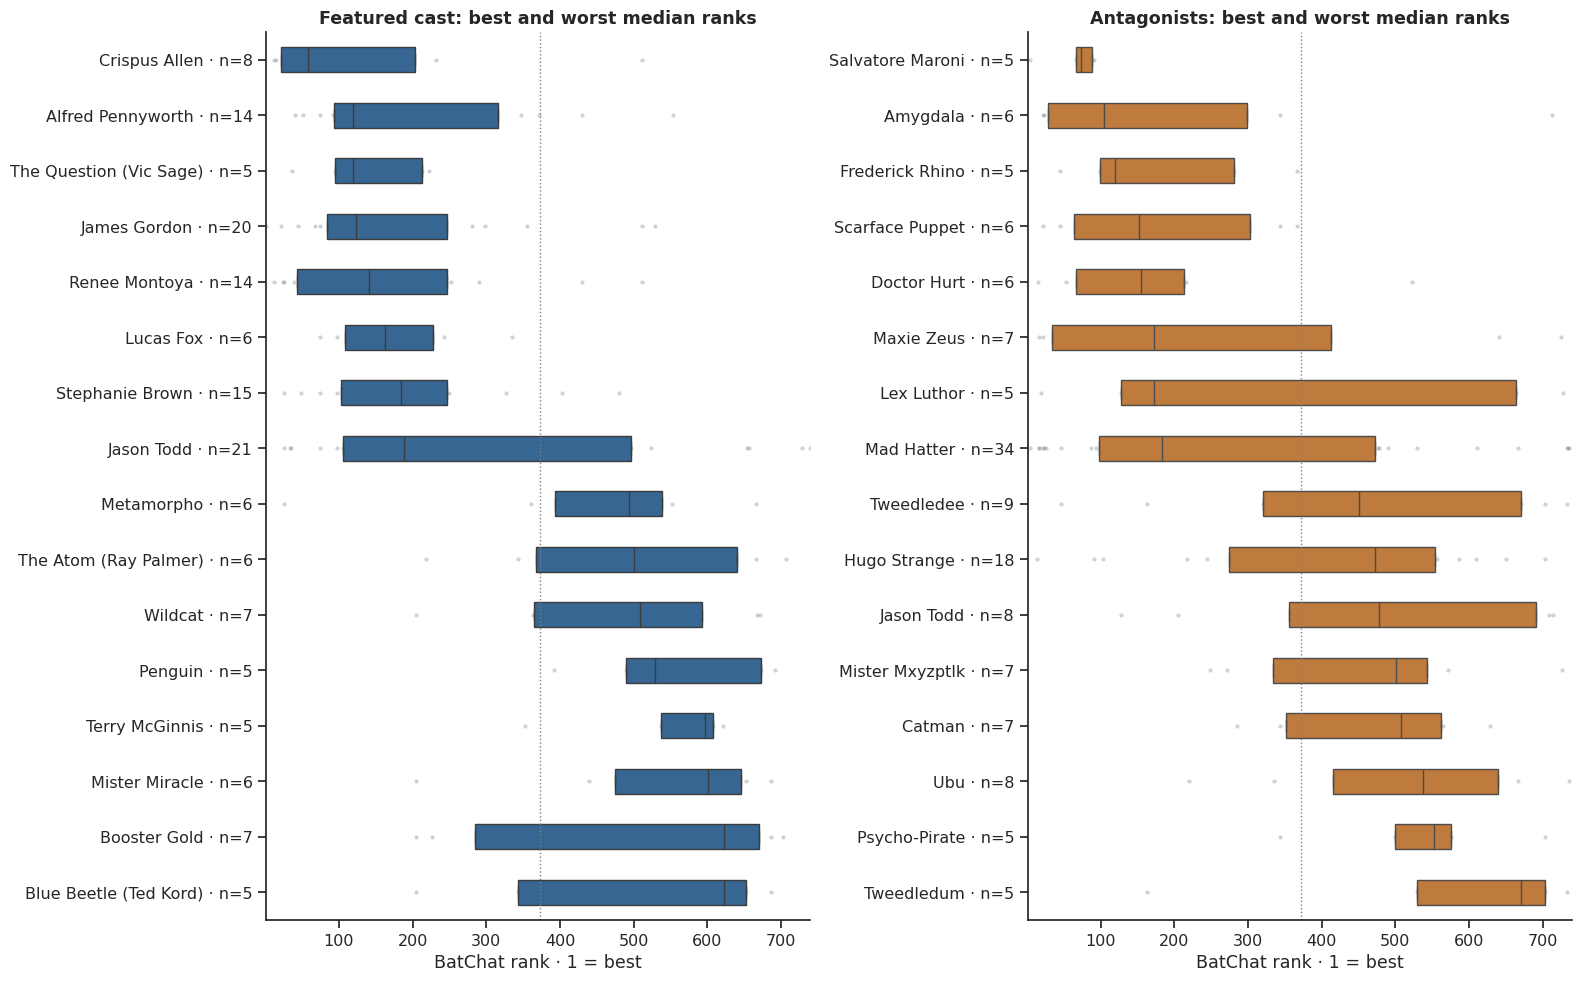

In [5]:
groups = {
    "Gotham City Police Department",
    "Batman Family",
    "Justice League of America",
    "Birds of Prey",
    "Justice League",
    "Outsiders",
    "Falcone Crime Family",
    "Vampires",
    "Man-Bat Commandos",
    "Gotham Organized Crime",
    "Dinosaurs",
    "Batman Villains",
    "Kobra Cult",
    "Nazi Party",
    "Secret Society of Super-Villains",
    "Court of Owls",
    "League of Assassins",
    "Zombies",
    "False Face Society",
    "Tweedledum and Tweedledee",
    "Regime",
    "Demons",
}
fig, axes = plt.subplots(1, 2, figsize=(16, 10), sharex=True)
for ax, (role, table), color in zip(axes, profiles.items(), [COLORS["blue"], COLORS["orange"]]):
    named = table[table.n.ge(5) & ~table.index.isin(groups)]
    extremes = pd.concat([named.head(8), named.tail(8)]).loc[lambda t: ~t.index.duplicated()]
    labels = extremes.display_name + " · n=" + extremes.n.astype(str)
    rank_boxes(ax, entries[role], "entity", labels, color)
    ax.axvline(cast_known["rank"].median(), ls=":", color=COLORS["grey"], lw=1)
    ax.set_title(f"{role}: best and worst median ranks")
    display(
        collapsible(
            f"{role}: best- and worst-ranked examples",
            extremes[list(PRETTY)].rename(columns=PRETTY),
            "Lower is better. Best and worst refer to this character's stories.",
            index=False,
        )
    )
fig.tight_layout()
plt.show()

## Gorilla watch. Shark watch.

**The Joker's Five-Way Revenge** (#11) features a shark tank. **Three Jokers** (#740) features a Jokerized shark. That is quite a range.

Each dot is a story, sorted by rank; the color says what was sighted. Neither animal has a clear edge: both spread across the whole list. These are checked sightings from the available synopses and cast lists, including cameos and flashbacks. King Shark, robot gorillas, and splicers (human–animal hybrids) get their own labels. Tiger Shark and Great White Shark are human villains, so they don't count. A story missing from the chart is unconfirmed, not animal-free.

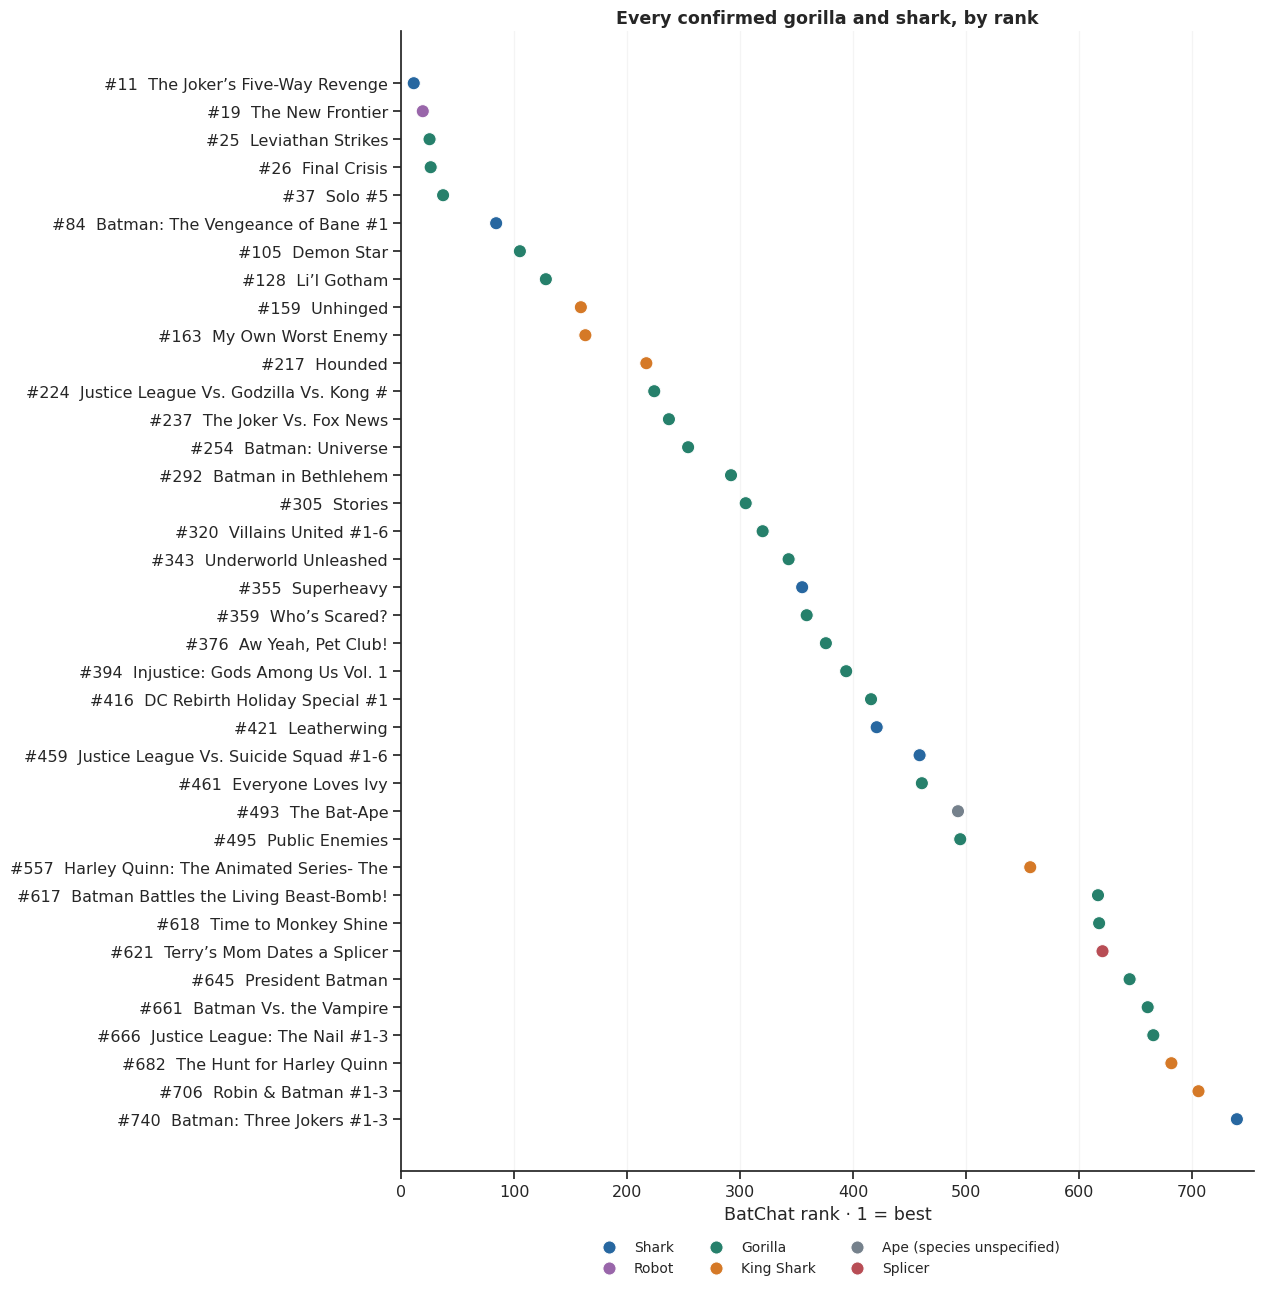

In [6]:
animal_watch = pd.read_csv(DATA / "animal_watch.csv")
kinds = {
    "gorilla": "Gorilla",
    "ape": "Ape (species unspecified)",
    "shark": "Shark",
    "shark_person": "King Shark",
    "robot": "Robot",
    "splicer": "Splicer",
}
sightings = (
    animal_watch[animal_watch.classification.isin(kinds)]
    .merge(stories[["story_id", "title", "rank"]], on="story_id", validate="many_to_one")
    .assign(kind=lambda d: d.classification.map(kinds))
)
# One point per story and animal family; keep the more specific identification.
sightings = sightings.sort_values(
    "classification", key=lambda x: x.map({"gorilla": 0, "ape": 1}).fillna(2)
)
sightings["family"] = sightings.animal.replace({"ape": "gorilla"})
sightings = sightings.drop_duplicates(["story_id", "family"]).sort_values("rank")
sightings["label"] = sightings["rank"].map("#{}".format) + "  " + sightings.title.str.slice(0, 38)

palette = dict(
    zip(kinds.values(), ["#26806B", "#75818C", "#2767A0", "#D57927", "#9966AA", "#B84D55"])
)
fig, ax = plt.subplots(figsize=(11, 0.32 * len(sightings) + 2))
sns.scatterplot(data=sightings, x="rank", y="label", hue="kind", palette=palette, s=90, ax=ax)
ax.set(
    xlabel="BatChat rank · 1 = best",
    ylabel="",
    xlim=(0, N + 15),
    title="Every confirmed gorilla and shark, by rank",
)
ax.legend(
    title="", loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=3, fontsize=10, frameon=False
)
ax.grid(axis="x", alpha=0.2)
plt.show()

## Mad Hatter outranks the Joker. Here's the trick.

Mad Hatter's median rank (**183.5**) beats Joker's (**296.5**) and Two-Face's (**302**). The source lists **Jervis Tetch as an antagonist** in 34 ranked stories. But *The Long Halloween* (#4), *Dark Victory* (#16), and *Final Crisis* (#26) are not Hatter stories; he is one villain among many, and each contributes its full rank to his median. The same rule applies to everyone:

In [7]:
compared_villains = ["Jervis Tetch", "Joker", "Bane", "Ra's al Ghul", "Harvey Dent"]
display(
    profiles["Antagonists"]
    .loc[compared_villains, ["display_name", "n", "median_rank", "best_story", "worst_story"]]
    .rename(
        columns={
            "display_name": "Antagonist",
            "n": "Stories",
            "median_rank": "Median rank",
            "best_story": "Highest-ranked book",
            "worst_story": "Lowest-ranked book",
        }
    )
    .reset_index(drop=True)
)

,Antagonist,Stories,Median rank,Highest-ranked book,Lowest-ranked book
0,Mad Hatter,34,183.5,The Long Halloween,Odyssey
1,Joker,112,296.5,The Long Halloween,Batman: Three Jokers #1-3
2,Bane,17,197.0,Knightfall Part 1: The Broken Bat,Odyssey
3,Ra's al Ghul,20,325.5,Tower of Babel,Odyssey
4,Two-Face,57,302.0,The Long Halloween,Batman: Three Jokers #1-3


### So we read all 34 Hatter stories

Reading the summaries and story lists gives **four clearly Hatter-led stories**: *Unknowing* (#142), *Madness* (#164), *The Scoop of the Century* (#478), and *Mad* (#733), median rank **321**. The **24 big-cast or collection entries** have a median of **149.5**. Six are unclear. That explains most of the surprise. It does **not** show that Hatter-led stories beat Joker- or Bane-led ones; we haven't reviewed their roles the same way.

Source roles need care too. In *Escape to Blackgate*, Hatter actually helps Nightwing fool Lock-Up (a minor villain), yet the wiki files him as an antagonist. `hatter_story_roles.csv` records every decision, its uncertainty, and the source revisions.

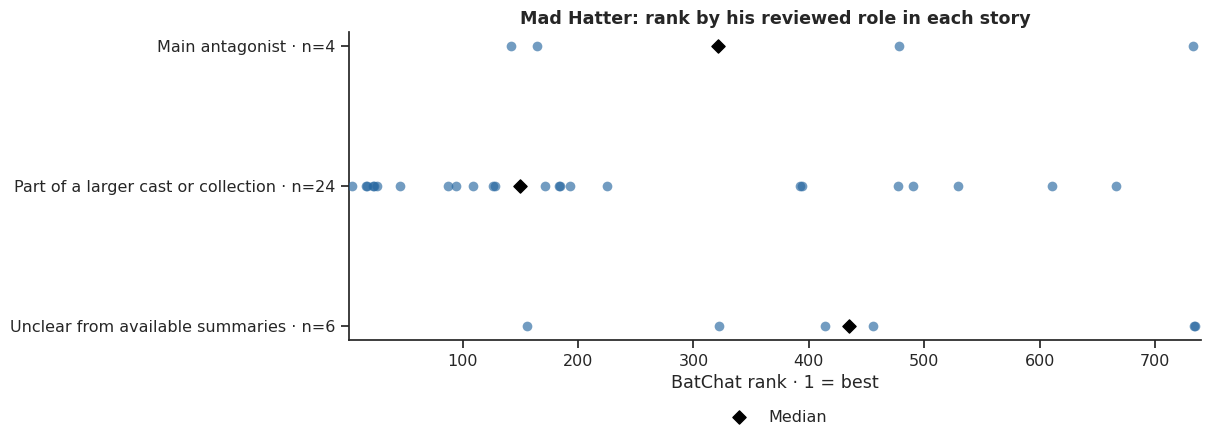

In [8]:
hatter_roles = pd.read_csv(DATA / "hatter_story_roles.csv")
role_order = [
    "Main antagonist",
    "Part of a larger cast or collection",
    "Unclear from available summaries",
]
role_summary = (
    hatter_roles.groupby("reviewed_role")["rank"]
    .agg(stories="size", median_rank="median")
    .reindex(role_order)
)

fig, ax = plt.subplots(figsize=(11, 4))
sns.stripplot(
    data=hatter_roles,
    x="rank",
    y="reviewed_role",
    order=role_order,
    color=COLORS["blue"],
    jitter=False,
    size=7,
    alpha=0.65,
    ax=ax,
)
ax.scatter(
    role_summary.median_rank, range(3), marker="D", color="black", s=45, label="Median", zorder=4
)
ax.set_yticks(range(3), [f"{role} · n={role_summary.loc[role, 'stories']}" for role in role_order])
ax.set(
    xlabel="BatChat rank · 1 = best",
    ylabel="",
    xlim=(1, N),
    title="Mad Hatter: rank by his reviewed role in each story",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.show()

### Is it the villain, or the era?

Separately, could **publication decade and story length** explain these averages? Each antagonist's stories are compared with other stories from the same decade and of similar length. This still counts any antagonist appearance, not just leading roles.

Orange dots: the rank gap when each antagonist's stories are compared with all the others. Blue dots: when they are compared only with stories of the same decade and length. **Negative means stories with that antagonist rank better.**

<details><summary>How the comparison works</summary>

Length groups are 1, 2–4, and 5+ issues. Each decade/length group needs at least three stories with the antagonist and three without. We average the within-group gaps, weighted by the number of stories with the antagonist.

The counts beside the names show how many stories had enough same-decade, same-length comparisons: the League of Assassins keeps 12 of 26. Small numbers; treat these as hints.

</details>

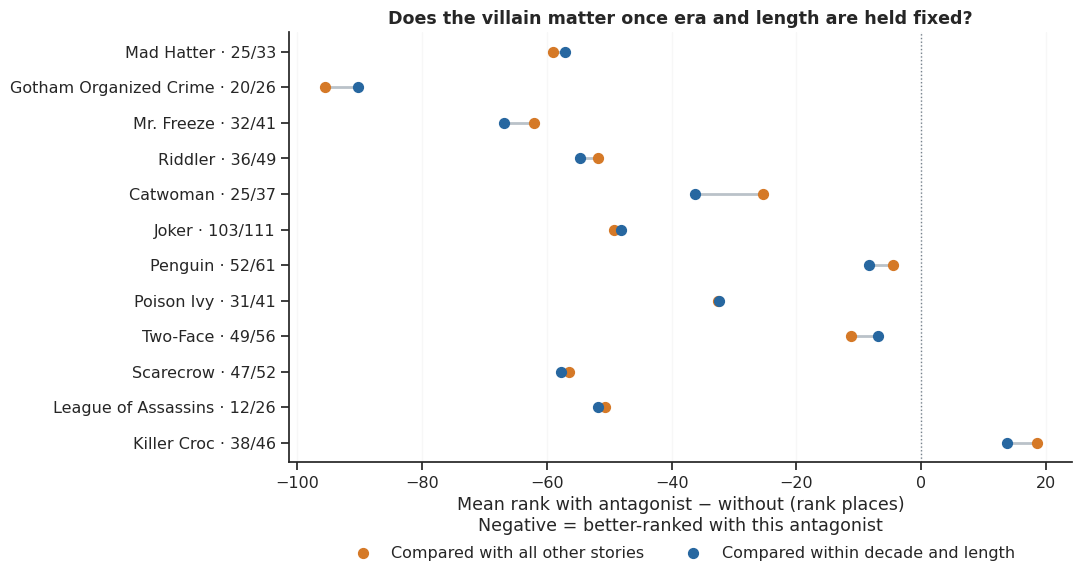

In [9]:
comparison = cast_known.dropna(subset=["decade"]).copy()
comparison["length_band"] = pd.cut(
    comparison.issue_count, [0, 1, 4, np.inf], labels=["1 issue", "2–4 issues", "5+ issues"]
)
comparison = comparison.dropna(subset=["length_band"])
frequent_antagonists = profiles["Antagonists"].nlargest(12, "n").sort_values("median_rank")
rows = []
for name in frequent_antagonists.index:
    with_name = antagonists.loc[antagonists.entity.eq(name), "story_id"]
    sample = comparison.assign(present=comparison.story_id.isin(with_name))
    stats = (
        sample.groupby(["decade", "length_band", "present"], observed=True)["rank"]
        .agg(["mean", "size"])
        .unstack("present")
    )
    ok = stats["size"].ge(3).all(axis=1)  # at least three stories with and three without
    matched = sample.set_index(["decade", "length_band"]).loc[ok[ok].index]
    rows.append(
        {
            "entity": name,
            "available": sample.present.sum(),
            "retained": matched.present.sum(),
            "pooled_gap": matched.loc[matched.present, "rank"].mean()
            - matched.loc[~matched.present, "rank"].mean(),
            "within_gap": np.average(
                (stats["mean"][True] - stats["mean"][False])[ok], weights=stats["size"][True][ok]
            ),
        }
    )
era_check = pd.DataFrame(rows).set_index("entity")

fig, ax = plt.subplots(figsize=(11, 6))
positions = range(len(era_check))
for pos, row in zip(positions, era_check.itertuples()):
    ax.plot([row.pooled_gap, row.within_gap], [pos, pos], color="#BAC2C9", lw=2)
ax.scatter(
    era_check.pooled_gap,
    positions,
    color=COLORS["orange"],
    label="Compared with all other stories",
    s=50,
    zorder=3,
)
ax.scatter(
    era_check.within_gap,
    positions,
    color=COLORS["blue"],
    label="Compared within decade and length",
    s=50,
    zorder=3,
)
ax.axvline(0, color=COLORS["grey"], ls=":", lw=1)
ax.set(
    yticks=positions,
    yticklabels=[
        f"{display_names.get(name, name)} · {int(row.retained)}/{int(row.available)}"
        for name, row in era_check.iterrows()
    ],
    xlabel="Mean rank with antagonist − without (rank places)\nNegative = better-ranked with this antagonist",
    title="Does the villain matter once era and length are held fixed?",
)
ax.invert_yaxis()
ax.xaxis.grid(True, alpha=0.15)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
fig.tight_layout()
plt.show()

Holding decade and length fixed leaves Hatter's gap largely intact. That doesn't fix the big-cast problem: a small role in a highly ranked book still counts. These checks address era and issue count, not how much a character matters to the story.

In [10]:
# Plot summaries: one document per story, only for stories whose every selected summary is present.
texts = pd.read_csv(DATA / "story_texts.csv")
available = texts[texts.text_status.eq("available")].copy()
# Identical summaries (ignoring case and spacing) count once per story.
available["text_key"] = available.synopsis_text.str.casefold().str.split().str.join(" ")
plot_text = (
    available.drop_duplicates(["story_id", "text_key"])
    .groupby("story_id")
    .synopsis_text.agg("\n\n".join)
)
complete = texts.text_status.eq("available").groupby(texts.story_id).all()
complete_plots = (
    stories.loc[
        stories.story_id.map(complete).fillna(False) & stories.issue_list_complete,
        ["story_id", "title", "rank"],
    ]
    .assign(plot_text=lambda d: d.story_id.map(plot_text))
    .reset_index(drop=True)
)
print(f"{len(complete_plots)} stories with complete plot summaries")

481 stories with complete plot summaries


## Riddler's puzzles, Penguin's business

Which words set a villain's stories apart? Larger words below are **more common in that villain's plot summaries than in everyone else's**. A word must appear in at least five of the villain's stories. The clouds are shaped like a question mark and an umbrella. Only stories with complete summaries are used; **rankings play no part here.**

<details><summary>How the comparison works</summary>

Word size is the log2 ratio of how often the word appears in each group, after adding one to the word counts and two to the group sizes so rare words don't dominate. A score of 1 means twice as common. Only positive scores appear. Each cloud has its own scale; color and position carry no information.

</details>

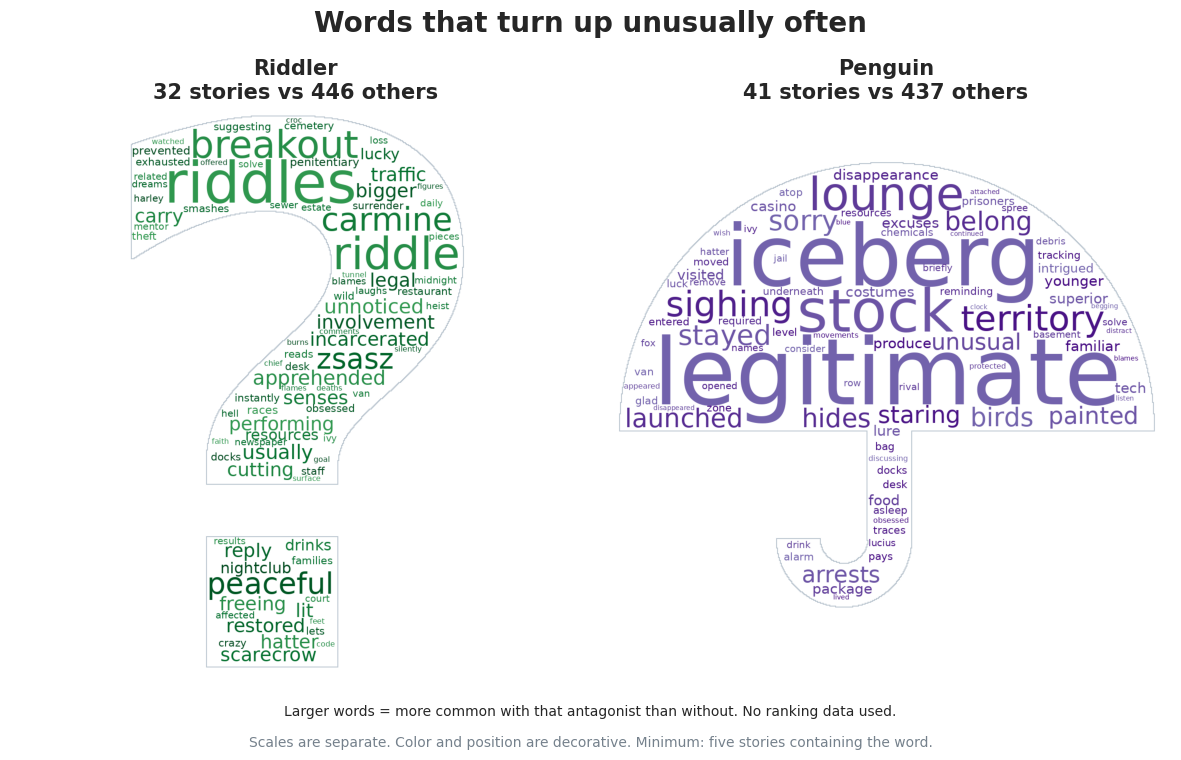

With this antagonist Other stories
Antagonist Word                                         
Riddler    riddle                  15 / 32       4 / 446
           scarecrow               12 / 32      16 / 446
Penguin    iceberg                 11 / 41       3 / 437
           legitimate               5 / 41       0 / 437

In [11]:
from matplotlib.colors import ListedColormap
from matplotlib.font_manager import findfont
from PIL import Image, ImageDraw, ImageFont
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
from wordcloud import WordCloud

extra_stopwords = set(
    """batman bruce wayne gotham city robin dick grayson tim drake
    jason todd alfred gordon riddler edward nashton nigma nygma penguin oswald cobblepot
    tells says asks comes goes gets just later soon new man men time way back
    couldn didn doesn isn wasn wouldn don ve ll aren weren hasn hadn haven shouldn needn mustn mightn won shan""".split()
)
vectorizer = CountVectorizer(
    binary=True,
    min_df=3,
    stop_words=sorted(ENGLISH_STOP_WORDS | extra_stopwords),
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
)
word_presence = vectorizer.fit_transform(complete_plots.plot_text)  # stories × words, 1 = present
terms = vectorizer.get_feature_names_out()

# Drawn silhouettes (a question mark, an umbrella) as cloud masks; 0 = draw here.
question = Image.new("L", (600, 600), 255)
draw = ImageDraw.Draw(question)
font = ImageFont.truetype(findfont("DejaVu Sans:weight=bold"), 780)
x0, y0, x1, y1 = draw.textbbox((0, 0), "?", font=font)
draw.text(((600 - x1 + x0) / 2 - x0, (600 - y1 + y0) / 2 - y0), "?", font=font, fill=0)
umbrella = Image.new("L", (600, 600), 255)
draw = ImageDraw.Draw(umbrella)
draw.pieslice((20, 60, 580, 620), 180, 360, fill=0)
draw.rectangle((280, 300, 325, 455), fill=0)
draw.arc((185, 385, 325, 525), 0, 180, fill=0, width=45)
masks = {
    "Riddler": np.where(np.array(question) < 128, 0, 255).astype("uint8"),
    "Penguin": np.array(umbrella),
}
font_path = findfont("DejaVu Sans")


def word_cloud(frequencies, mask, colors, max_words):
    return WordCloud(
        mask=mask,
        background_color="white",
        font_path=font_path,
        random_state=42,
        max_words=max_words,
        scale=2,
        prefer_horizontal=1,
        colormap=ListedColormap(colors),
        contour_width=1,
        contour_color="#BBC6D0",
    ).generate_from_frequencies(frequencies)


has_cast = complete_plots.story_id.isin(cast_known.story_id).to_numpy()
cohorts = {
    "Riddler": {"Riddler", "J. Edward Nygma"},  # Nashton/Nigma/Nygma already folded into "Riddler"
    "Penguin": {"Oswald Cobblepot", "Penguin"},
}
word_stats = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 7.8))
for ax, (villain, names), palette in zip(axes, cohorts.items(), ["Greens", "Purples"]):
    with_villain = antagonists.loc[antagonists.entity.isin(names), "story_id"]
    present = complete_plots.story_id.isin(with_villain).to_numpy() & has_cast
    other = has_cast & ~present
    counts = word_presence[present].sum(axis=0).A1
    other_counts = word_presence[other].sum(axis=0).A1
    score = np.log2(((counts + 1) / (present.sum() + 2)) / ((other_counts + 1) / (other.sum() + 2)))
    score = pd.Series(score, index=terms)[(counts >= 5) & (score > 0)].nlargest(85)
    word_stats[villain] = pd.DataFrame({"with": counts, "other": other_counts}, index=terms).assign(
        with_total=present.sum(), other_total=other.sum()
    )
    colors = plt.get_cmap(palette)(np.linspace(0.70, 0.98, 8))
    ax.imshow(word_cloud(score.to_dict(), masks[villain], colors, 85))
    ax.axis("off")
    ax.set_title(f"{villain}\n{present.sum()} stories vs {other.sum()} others", fontsize=15)
fig.suptitle("Words that turn up unusually often", fontsize=20, fontweight="bold")
fig.text(
    0.5,
    0.075,
    "Larger words = more common with that antagonist than without. No ranking data used.",
    ha="center",
    fontsize=10,
)
fig.text(
    0.5,
    0.035,
    "Scales are separate. Color and position are decorative. Minimum: five stories containing the word.",
    ha="center",
    fontsize=10,
    color=COLORS["grey"],
)
fig.tight_layout(rect=(0, 0.10, 1, 0.94))
plt.show()

examples = pd.concat(
    [
        word_stats["Riddler"].loc[["riddle", "scarecrow"]],
        word_stats["Penguin"].loc[["iceberg", "legitimate"]],
    ],
    keys=["Riddler", "Penguin"],
    names=["Antagonist", "Word"],
)
pd.DataFrame(
    {
        "With this antagonist": examples["with"].astype(str)
        + " / "
        + examples.with_total.astype(str),
        "Other stories": examples.other.astype(str) + " / " + examples.other_total.astype(str),
    }
)

"Riddle" appears in **15 of 32** Riddler stories, versus **4 of 446** others. "Scarecrow" appears in **12 of 32**, versus **16 of 446**: the clouds catch the company he keeps as well as his gimmick.

Penguin gets "iceberg": **11 of 41**, versus **3 of 437**. "Legitimate" appears in **5 of 41** and in none of the others. A respectable-looking business is familiar Penguin territory, though that big word rests on just five stories.

Summary length matters too. Riddler and Penguin summaries have median lengths of **1,422 and 1,200 words**, against **552** for both comparison groups, and longer summaries have more chances to mention any word. These clouds describe wiki summaries, not the comics' dialogue or prose.


## Three villains worth a second look

- **Mad Hatter:** best median among the big names, until you check who the story is actually about.
- **Salvatore Maroni:** five stories, median #73, and he is barely in any of them.
- **Penguin:** "iceberg" and "legitimate" are his words. Business is the gimmick.

**More BatChat notebooks:** [Who gets the good Batman stories?](https://www.kaggle.com/code/danofer/who-gets-the-good-batman-stories) · [What Batman plots are made of](https://www.kaggle.com/code/danofer/what-batman-plots-are-made-of) · [Can a computer predict BatChat's favorites?](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories) · [BatChat vs the crowd](https://www.kaggle.com/code/danofer/batchat-vs-the-crowd-where-batman-fans-disagree) · [The dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)

If you enjoyed this, an upvote helps other Batman fans find it.